### RaschPy mixed MFRM worked example

In a mixed many-facet Rasch model, each rater has their own representation: one of `global`, `items`, `thresholds`, `bivector`, `matrix`, `centrality`, `pseudo_halo` or `bistretch`. This notebook simulates data from ten raters with known representations (400 persons, 12 items with a maximum score of 4, every person rated by every rater, no missing data). It then assigns each rater a representation with `per_rater_model_selection()`, compares the assigned representations with the generating ones, and works through the selected fit.

In [1]:
import raschpy as rp
import numpy as np
import pandas as pd
import os

os.chdir('my_working_directory')

#### Data

`rater_models` gives each rater's representation, with values drawn at random. Raters 1, 2 and 10 are the anchors: with `neutral_anchors=True` they are generated with no effect at all, and the true values of the other raters' effects are reported relative to them. `seed=2026` makes the simulation reproducible.

In [2]:
rater_models = ['global', 'global', 'items', 'thresholds', 'bivector',
                'matrix', 'centrality', 'pseudo_halo', 'bistretch', 'global']
anchors = ['Rater_1', 'Rater_2', 'Rater_10']

sim = rp.MFRM_Sim(no_of_items=12,
                  no_of_persons=400,
                  no_of_facet_elements=10,
                  max_score=4,
                  model='mixed',
                  rater_models=dict(zip([f'Rater_{r}' for r in range(1, 11)], rater_models)),
                  anchors=anchors,
                  neutral_anchors=True,
                  seed=2026)
sim.responses.to_csv('mfrm_mixed_scores.csv')

If you have your own response data saved to a CSV file instead, load and validate it with `loadup_mfrm_single()`. Demonstrated here by reloading the file just saved:

In [3]:
data, invalid_responses = rp.loadup_mfrm_single('mfrm_mixed_scores.csv',
                                                max_score=4)
data.head(2)

Item_1  Item_2  Item_3  Item_4  Item_5  Item_6  Item_7  \
Rater   Person                                                             
Rater_1 Person_1     2.0     1.0     1.0     1.0     0.0     0.0     1.0   
        Person_2     2.0     2.0     3.0     0.0     1.0     1.0     1.0   

                  Item_8  Item_9  Item_10  Item_11  Item_12  
Rater   Person                                               
Rater_1 Person_1     1.0     1.0      0.0      1.0      1.0  
        Person_2     2.0     1.0      3.0      1.0      1.0

Create an MFRM object. Passing the simulation object `sim` (rather than `data`) attaches the generating values under `mfrm.generating`, for the recovery checks below. For your own data, pass a DataFrame instead (`rp.MFRM(data)`).

In [4]:
mfrm = rp.MFRM(sim)

#### 1. Checking the anchor set

The anchors' average defines the zero point, so before relying on them, check that they agree with each other, in global effect and in their pattern over items and thresholds. `check_anchor_homogeneity()` uses the anchors' responses only (the Anchor calibration example demonstrates it in full):

To run the analysis using conditional maximum likelihood (CML) estimation (Andersen, 1970), pass `estimation='cml'` to `check_anchor_homogeneity()` and `per_rater_model_selection()`; the methods after them follow the fit's estimation. With CML, `per_rater_model_selection()` takes about ten minutes here, rather than about ten seconds.

In [5]:
check = mfrm.check_anchor_homogeneity(anchors=anchors)
check

Anchor check (cp-full-rcl, the anchors' responses only)
  AnchorSet(anchors=['Rater_1', 'Rater_2', 'Rater_10'])

Overall agreement
  items          LR p = 0.464
  thresholds     LR p = 0.521
  global effect  Wald p = 0.015
  overall p = 0.045 (Holm)  -> anchors disagree on global effect

Screen, pattern, round 1 (each anchor against the rest; BH across anchors)
  Rater_1      global                     p = 1.000   
  Rater_2      global                     p = 1.000   
  Rater_10     global                     p = 1.000   

Screen, global effect, round 1 (each anchor against the rest; BH across anchors)
  Rater_1      shift +0.044 (SE 0.022)    p = 0.045   
  Rater_2      shift +0.018 (SE 0.025)    p = 0.466   
  Rater_10     shift -0.062 (SE 0.023)    p = 0.007   flagged, resolved

Screen, global effect, round 2 (each anchor against the rest; BH across anchors)
  Rater_1      shift +0.017 (SE 0.027)    p = 0.523   
  Rater_2      shift -0.017 (SE 0.027)    p = 0.523   

Suggested adju

The three anchors were generated identical, yet the global effect screen flags Rater_10: it is 0.062 logits more lenient than the other two (SE 0.023, p = 0.007), and the suggestion is to drop it. This is sampling error: in simulations with identical anchors (5 anchors, 400 persons), a good anchor was changed in 0.033 of datasets, and this dataset is one of them. Keeping Rater_10 moves the zero point by 0.021 logits (the last column), too little to matter for most purposes. `min_effect=` sets the smallest difference worth acting on:

In [6]:
mfrm.check_anchor_homogeneity(anchors=anchors, min_effect=0.1)

Anchor check (cp-full-rcl, the anchors' responses only)
  AnchorSet(anchors=['Rater_1', 'Rater_2', 'Rater_10'])

Overall agreement
  items          LR p = 0.464
  thresholds     LR p = 0.521
  global effect  Wald p = 0.015
  overall p = 0.045 (Holm)  -> anchors disagree on global effect

Screen, pattern, round 1 (each anchor against the rest; BH across anchors)
  Rater_1      global                     p = 1.000   
  Rater_2      global                     p = 1.000   
  Rater_10     global                     p = 1.000   

Screen, global effect, round 1 (each anchor against the rest; BH across anchors)
  Rater_1      shift +0.044 (SE 0.022)    p = 0.045   
  Rater_2      shift +0.018 (SE 0.025)    p = 0.466   
  Rater_10     shift -0.062 (SE 0.023)    p = 0.007   

No adjustments suggested.

With differences under 0.1 logits set aside, nothing is suggested, and the anchors are kept as they are. The overall test still reports the statistical difference (overall p = 0.045); `min_effect` governs only what the check suggests.

#### 2. Per-rater model selection

Each candidate representation for a rater is a joint fit of all raters (`calibrate(model='mixed')`), with the other raters on their current representations. The candidates are compared by AIC, and a representation more complex than `global` is kept only if it beats `global` at `alpha=0.05` (`aic_sig_test=True`). The default `scheme='iterate'` starts with every non-anchor rater on `matrix` and updates one rater at a time until a pass changes nothing. The anchors are held on `global`: they define the zero point, and each other rater is compared with them; without `anchors=`, each rater would be compared with the average rater (see section 4).

In [7]:
%%time
mfrm.per_rater_model_selection(anchors=anchors)
round(mfrm.per_rater_model_selection_table, 1)

CPU times: user 7.23 s, sys: 894 ms, total: 8.13 s
Wall time: 7.98 s


,Representation,Note,AIC global,AIC items,AIC thresholds,AIC bivector,AIC matrix,AIC centrality,AIC pseudo_halo,AIC bistretch,Best,Baseline,p
rater,,,,,,,,,,,,,
Rater_1,global,anchor (held on 'global'),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rater_2,global,anchor (held on 'global'),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rater_3,items,NaN,574765.804315,566925.55302,573778.452861,566972.582231,567528.390876,573829.388642,573530.682922,573274.397396,items,global,0.0
Rater_4,thresholds,NaN,568766.504002,568786.62946,566925.55302,566963.757966,567623.56088,568548.938408,568731.982554,568558.899942,thresholds,global,0.0
Rater_5,bivector,NaN,576339.648909,569350.685869,572564.786191,566925.55302,567170.723553,573016.066806,576360.091833,572573.070558,bivector,global,0.0
Rater_6,matrix,NaN,575955.16036,568878.601273,572366.605389,567438.226444,566925.55302,573629.748533,575665.365997,573643.304374,matrix,global,0.0
Rater_7,thresholds,NaN,567135.77233,567260.569339,566925.55302,567063.084705,567553.861466,566970.559462,567133.524657,566987.43,thresholds,global,0.001033
Rater_8,global,NaN,566925.55302,567015.53782,567010.269854,567091.300557,567531.96994,566946.769212,566917.738876,566934.283423,pseudo_halo,global,0.594863
Rater_9,bistretch,NaN,568480.822298,568495.879583,567471.347846,567073.836506,567223.156814,567470.321805,568401.793185,566925.55302,bistretch,global,0.0


In [8]:
mfrm.per_rater_model_selection_info

{'frame': "anchors ['Rater_1', 'Rater_2', 'Rater_10']",
 'anchors': ['Rater_1', 'Rater_2', 'Rater_10'],
 'test': 'AIC',
 'scheme': 'iterate',
 'passes': 2,
 'estimation': 'cp-full-rcl',
 'fits': 92,
 'converged_after_max_passes': True}

The anchors (Raters 1, 2 and 10) are not selected: their rows say they are held on `global`, and have no AIC values.

#### 3. Generating v selected representations

In [9]:
comparison = pd.DataFrame({'Generating': sim.rater_models,
                           'Selected': mfrm.rater_models})
comparison['Match'] = comparison['Generating'] == comparison['Selected']
comparison

,Generating,Selected,Match
Rater_1,global,global,True
Rater_2,global,global,True
Rater_3,items,items,True
Rater_4,thresholds,thresholds,True
Rater_5,bivector,bivector,True
Rater_6,matrix,matrix,True
Rater_7,centrality,thresholds,False
Rater_8,pseudo_halo,global,False
Rater_9,bistretch,bistretch,True
Rater_10,global,global,True


The generating values of the raters whose selected representation differs from their generating one:

In [10]:
mismatched = comparison.index[~comparison['Match']]
for rater in mismatched:
    print(rater, sim.rater_params[rater])

Rater_7 ('centrality', {'lambda': 0.2220742669836595, 'omega': 0.9050151769673738})
Rater_8 ('pseudo_halo', {'lambda': 0.2064547221943297, 'omega': 1.0055856347134884})


For each of these raters, the AIC of their generating and selected representations, with the other raters on their selected representations (from the last pass of the selection):

In [11]:
table = mfrm.per_rater_model_selection_table
pd.DataFrame({'Generating': comparison.loc[mismatched, 'Generating'],
              'AIC (generating)': [table.loc[r, f"AIC {comparison.loc[r, 'Generating']}"] for r in mismatched],
              'Selected': comparison.loc[mismatched, 'Selected'],
              'AIC (selected)': [table.loc[r, f"AIC {comparison.loc[r, 'Selected']}"] for r in mismatched]}).round(1)

,Generating,AIC (generating),Selected,AIC (selected)
Rater_7,centrality,566970.6,thresholds,566925.6
Rater_8,pseudo_halo,566917.7,global,566925.6


Rater 7's selected representation, `thresholds`, has the lower AIC; `centrality` is a restricted form of `thresholds`. Rater 8's generating representation, `pseudo_halo`, has the lower AIC, but its improvement on `global` did not pass the significance test (`aic_sig_test`), so `global` was kept. Rater 8's true item stretch, `omega` = 1.006, is close to 1 (no stretch), where `pseudo_halo` reduces to `global`.

How much does the difference matter? Fit the generating mix directly, then compare each fit's estimated rater effects with the true ones. The table gives, for each rater, the root mean square difference between the estimated and true effects over the rater's 48 item × threshold cells (in the anchors' frame):

In [12]:
mfrm_generating = rp.MFRM(sim)
mfrm_generating.calibrate(model='mixed',
                          rater_models=sim.rater_models.to_dict(),
                          anchors=anchors)

true_effects = sim.facet_effects.values
rmse = pd.DataFrame({
    'RMSE (generating mix)': ((mfrm_generating.facet_effects_mixed.values - true_effects) ** 2).reshape(10, -1).mean(axis=1) ** 0.5,
    'RMSE (selected mix)': ((mfrm.facet_effects_mixed.values - true_effects) ** 2).reshape(10, -1).mean(axis=1) ** 0.5},
    index=mfrm.facet_names)
pd.concat([comparison[['Generating', 'Selected']], rmse.round(3)], axis=1)

,Generating,Selected,RMSE (generating mix),RMSE (selected mix)
Rater_1,global,global,0.030,0.030
Rater_2,global,global,0.014,0.015
Rater_3,items,items,0.083,0.087
Rater_4,thresholds,thresholds,0.062,0.062
Rater_5,bivector,bivector,0.109,0.116
Rater_6,matrix,matrix,0.231,0.234
Rater_7,centrality,thresholds,0.031,0.097
Rater_8,pseudo_halo,global,0.044,0.016
Rater_9,bistretch,bistretch,0.056,0.061
Rater_10,global,global,0.044,0.044


#### 4. Why the anchors matter

Without `anchors=`, each rater is compared with the average rater. The average rater carries a share of every other rater's item and threshold effects, so a rater with no effects of their own differs from the average rater by item and by threshold:

In [13]:
%%time
mfrm_unanchored = rp.MFRM(sim)
mfrm_unanchored.per_rater_model_selection()
pd.DataFrame({'Generating': sim.rater_models,
              'Selected (anchors)': mfrm.rater_models,
              'Selected (no anchors)': mfrm_unanchored.rater_models})

CPU times: user 22 s, sys: 8.6 s, total: 30.6 s
Wall time: 17.1 s


,Generating,Selected (anchors),Selected (no anchors)
Rater_1,global,global,bivector
Rater_2,global,global,matrix
Rater_3,items,items,items
Rater_4,thresholds,thresholds,bivector
Rater_5,bivector,bivector,bivector
Rater_6,matrix,matrix,matrix
Rater_7,centrality,thresholds,bivector
Rater_8,pseudo_halo,global,items
Rater_9,bistretch,bistretch,bivector
Rater_10,global,global,bivector


#### 5. The selected fit

`per_rater_model_selection()` stores the joint fit with the selected representations, as `calibrate(model='mixed', rater_models=..., anchors=anchors)` would. The downstream methods take `model='mixed'`. Item statistics:

In [14]:
mfrm.item_stats_df(model='mixed', full=True)

,Estimate,SE,2.5%,97.5%,Count,Facility,Infit MS,Infit Z,Outfit MS,Outfit Z,PM corr,Exp PM corr
Item_1,-0.785,0.022,-0.829,-0.741,4000,0.619,0.967,-1.470,1.003,0.150,0.710,0.710
Item_2,0.306,0.023,0.260,0.351,4000,0.475,0.993,-0.293,0.977,-1.002,0.709,0.709
Item_3,-0.938,0.024,-0.986,-0.890,4000,0.624,0.961,-1.752,0.967,-1.457,0.745,0.739
Item_4,0.049,0.024,0.003,0.096,4000,0.497,1.010,0.431,1.013,0.584,0.708,0.705
Item_5,0.398,0.024,0.350,0.445,4000,0.418,0.987,-0.554,0.999,-0.025,0.713,0.714
Item_6,0.805,0.026,0.753,0.857,4000,0.334,0.987,-0.570,0.994,-0.254,0.728,0.721
Item_7,-0.296,0.023,-0.342,-0.250,4000,0.524,1.001,0.070,0.980,-0.886,0.711,0.708
Item_8,-0.456,0.022,-0.498,-0.414,4000,0.568,1.022,0.972,1.023,1.016,0.730,0.733
Item_9,-0.206,0.024,-0.252,-0.159,4000,0.519,0.986,-0.606,0.995,-0.230,0.712,0.708
Item_10,-0.833,0.024,-0.880,-0.787,4000,0.590,1.018,0.809,1.031,1.359,0.720,0.733


Threshold statistics:

In [15]:
mfrm.threshold_stats_df(model='mixed', full=True)

,Estimate,SE,2.5%,97.5%,Infit MS,Infit Z,Outfit MS,Outfit Z,Discrim,PM corr,Exp PM corr
Threshold 1,-2.011,0.024,-2.058,-1.963,1.003,0.368,1.001,0.068,0.996,0.770,0.777
Threshold 2,0.373,0.020,0.335,0.412,0.998,-0.335,0.994,-0.472,1.006,0.553,0.551
Threshold 3,0.623,0.022,0.579,0.667,0.993,-1.031,0.985,-1.311,1.024,0.426,0.412
Threshold 4,1.014,0.024,0.967,1.061,1.009,1.309,1.038,2.826,0.969,0.532,0.544


Each rater's effects, by representation (here the `items`, `thresholds` and `bistretch` raters):

In [16]:
round(mfrm.facet_effects_mixed_items, 3)

,Item_1,Item_2,Item_3,Item_4,Item_5,Item_6,Item_7,Item_8,Item_9,Item_10,Item_11,Item_12
Rater_3,-1.316,-0.965,-0.265,-0.689,-1.141,0.506,-0.056,-0.888,-1.445,0.309,-0.141,0.678


In [17]:
round(mfrm.facet_effects_mixed_thresholds, 3)

,1,2,3,4
Rater_4,-0.301,-0.962,-1.187,-0.461
Rater_7,0.381,0.149,0.263,-0.029


In [18]:
round(mfrm.facet_effects_mixed_bistretch, 3)

,lambda,omega_items,omega_thresholds
Rater_9,1.316,1.319,1.319


Every rater's effects are also stored in one layout, `facet_effects_mixed` (rater × item rows, threshold columns). Rater 6 (`matrix`):

In [19]:
round(mfrm.facet_effects_mixed.loc['Rater_6'], 3)

,1,2,3,4
item,,,,
Item_1,-0.315,-0.251,-0.829,-1.161
Item_2,-0.857,-1.502,-1.535,-1.940
Item_3,0.371,0.501,0.516,-0.239
Item_4,-1.070,-1.239,-2.045,-2.556
Item_5,0.360,-0.565,-0.932,-1.426
Item_6,-0.035,-0.223,0.192,-0.842
Item_7,-0.209,-1.884,-1.401,-1.906
Item_8,0.676,-1.055,-0.069,-1.448
Item_9,-0.049,-1.080,-0.424,-1.094


Person and test statistics:

In [20]:
mfrm.person_stats_df(model='mixed', full=True).head(10)

,Estimate,CSEM,RSEM,Score,Max score,p,Infit MS,Outfit MS,Infit Z,Outfit Z
Person_1,-1.171,0.119,0.110,122,480,0.254,0.865,0.880,-0.927,-0.836
Person_2,0.168,0.099,0.094,242,480,0.504,0.902,0.856,-0.790,-1.083
Person_3,-2.692,0.175,0.160,46,480,0.096,0.832,0.817,-1.008,-1.039
Person_4,2.046,0.129,0.133,409,480,0.852,1.072,0.947,0.493,-0.155
Person_5,0.808,0.101,0.094,307,480,0.640,0.864,0.941,-1.089,-0.363
Person_6,-0.629,0.107,0.112,165,480,0.344,1.091,1.112,0.703,0.834
Person_7,-0.687,0.108,0.093,160,480,0.333,0.739,0.792,-2.080,-1.589
Person_8,0.548,0.099,0.107,281,480,0.585,1.155,1.108,1.231,0.799
Person_9,-0.550,0.106,0.111,172,480,0.358,1.101,1.099,0.782,0.746
Person_10,-0.419,0.104,0.102,184,480,0.383,0.968,0.941,-0.205,-0.402


In [21]:
mfrm.test_stats_df(model='mixed')

,Items,Persons
Mean,0.000,-0.009
SD,0.697,1.574
Separation ratio,28.820,12.020
Strata,38.760,16.360
Reliability,0.999,0.993


#### 6. Parameter recovery

`recovery_stats()` compares the estimates with the generating values: items, thresholds, category widths, persons, and each representation's rater effects. Representations with a single rater have no regression line.

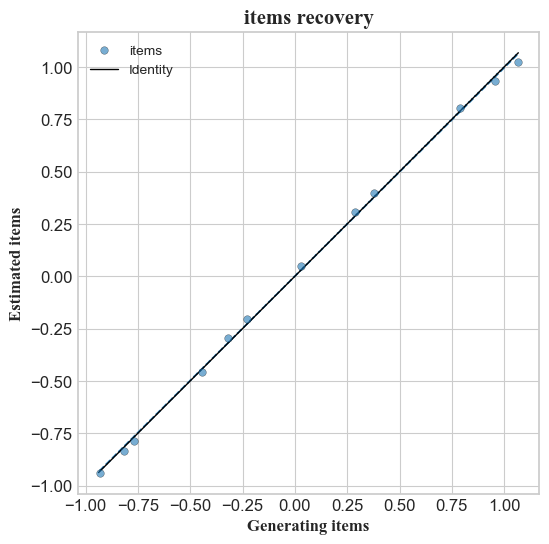

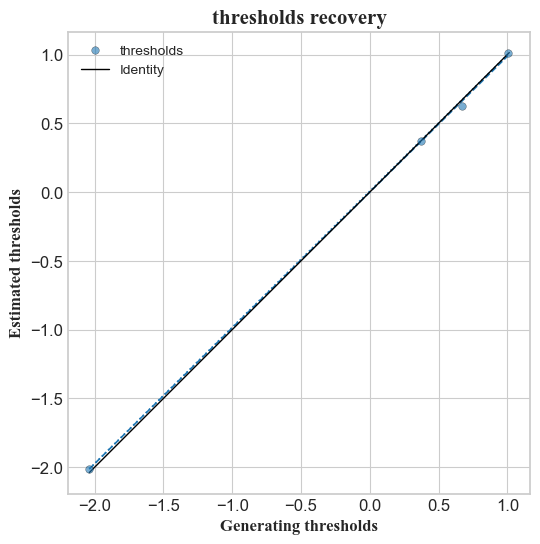

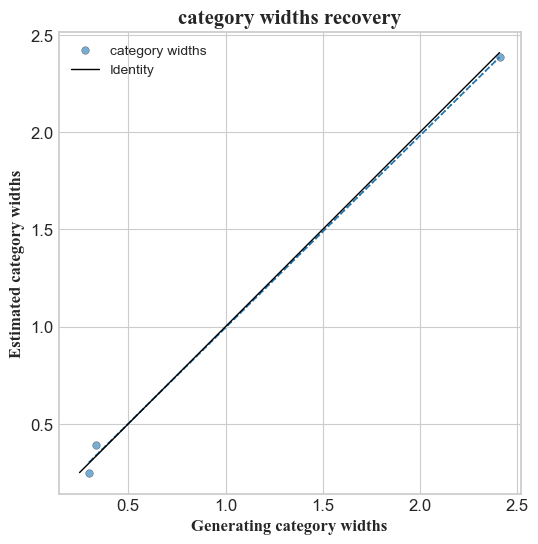

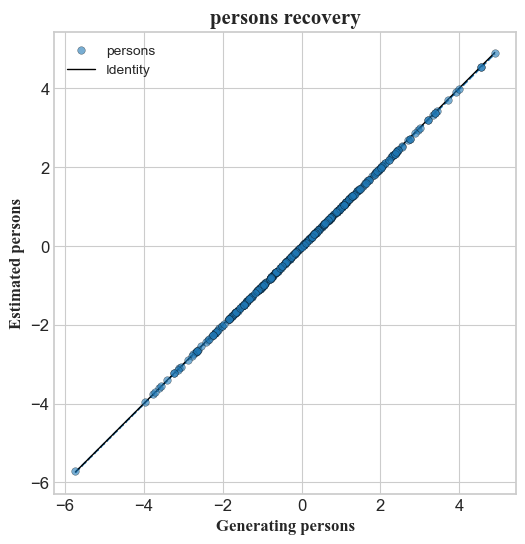

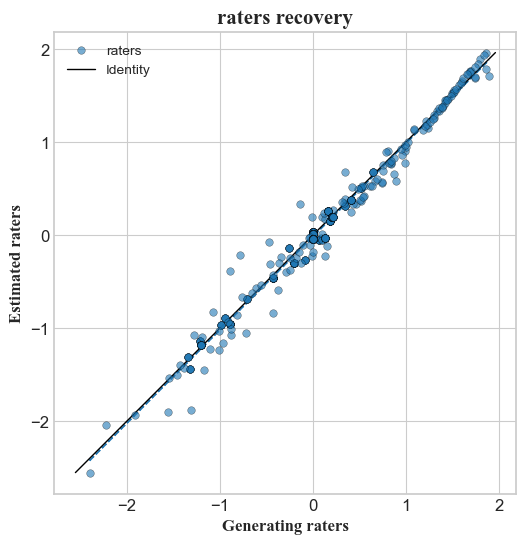

In [22]:
mfrm.recovery_stats(model='mixed')

In [23]:
mfrm.recovery.items.summary

,Overall
RMSE,0.021856
MAE,0.019765
bias,0.0
r,0.999473
r_squared,0.998946
SD_ratio,0.996336
OLS_slope,0.995811
OLS_intercept,-0.0
Huber_slope,0.999482
Huber_intercept,0.001544


#### 7. Plots

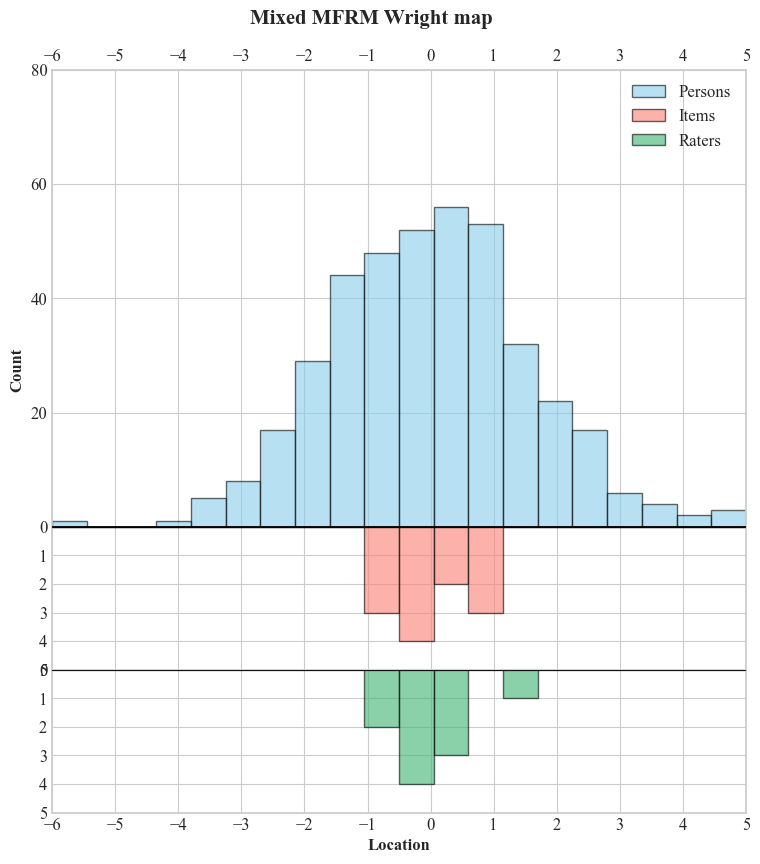

In [24]:
mfrm.wright_map(model='mixed',
                title='Mixed MFRM Wright map',
                filename='my_mfrm_mixed_wright_map')

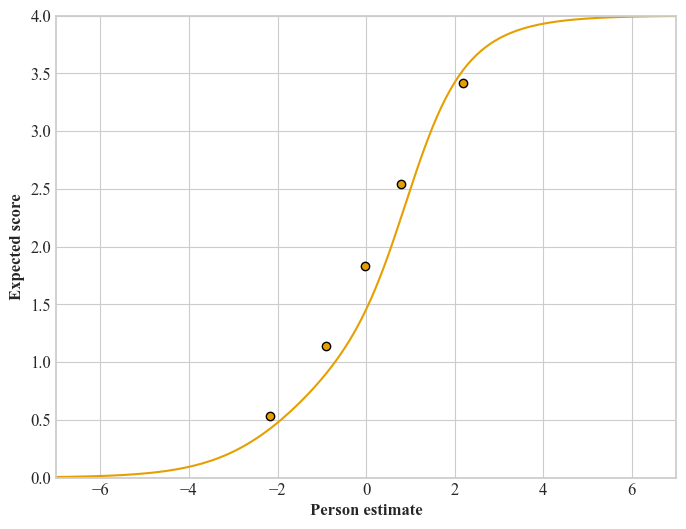

In [25]:
mfrm.icc(model='mixed',
         items='Item_2',
         obs=True,
         xmin=-7,
         xmax=7,
         filename='my_mfrm_mixed_icc')

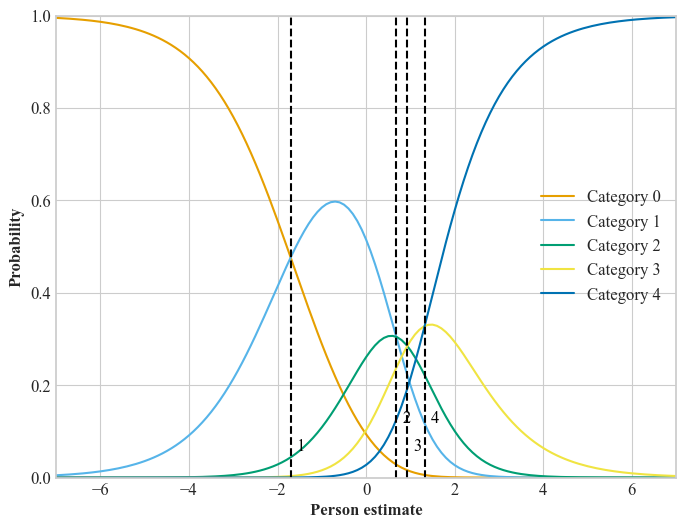

In [26]:
mfrm.crcs(model='mixed',
          item='Item_2',
          thresh_lines=True,
          xmin=-7,
          xmax=7,
          filename='my_mfrm_mixed_crcs')

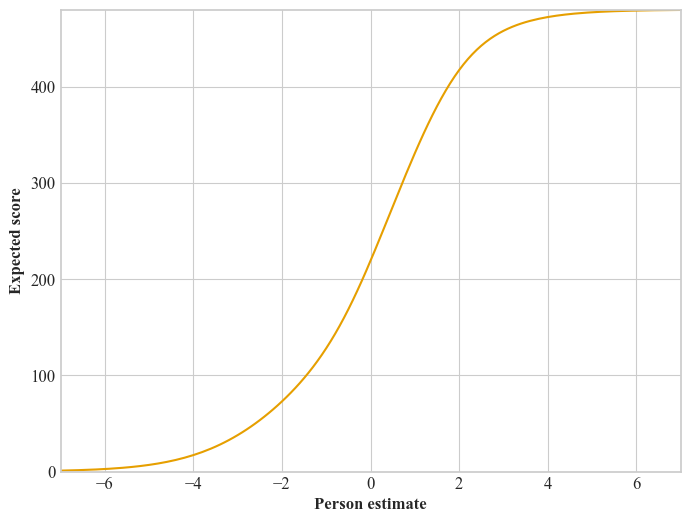

In [27]:
mfrm.tcc(model='mixed',
         xmin=-7,
         xmax=7,
         filename='my_mfrm_mixed_tcc')

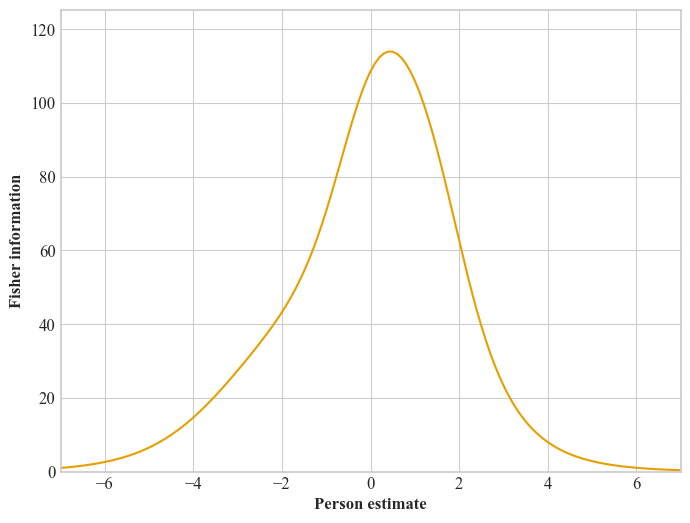

In [28]:
mfrm.test_info(model='mixed',
               xmin=-7,
               xmax=7,
               filename='my_mfrm_mixed_test_info')

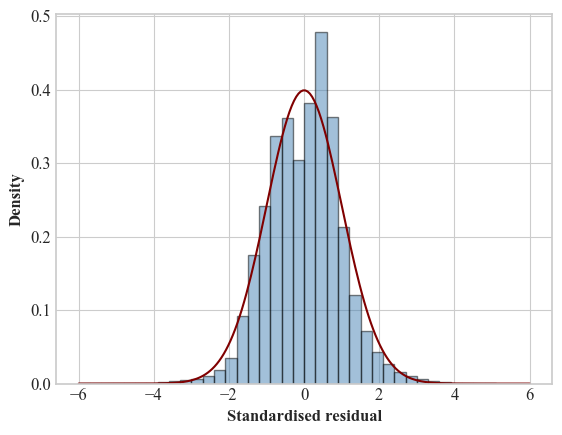

In [29]:
mfrm.std_residuals_plot(model='mixed',
                        bin_width=0.6,
                        normal=True,
                        filename='my_mfrm_mixed_std_residuals_plot')

#### References

Andersen, E. B. (1970). Asymptotic properties of conditional maximum-likelihood estimators. *Journal of the Royal Statistical Society, Series B*, 32(2), 283–301.